- <font size="3">PDF and CDF</font>
- <font size="3">Inversion sampling</font>
- <font size="3">Rejection sampling</font>
- <font size="3">2D distributions</font>
- <font size="3">Monte Carlo</font>

## Preamble

In [2]:
import numpy as np
import scipy
import matplotlib.pyplot as plt

MEDIUM_SIZE = 16
BIGGER_SIZE = 20

plt.rcdefaults()

#plt.rc('font',**{'family':'serif','serif':['Times']})
#plt.rc('text', usetex=True)

plt.rc('font', size=BIGGER_SIZE)          # controls default text sizes
plt.rc('axes', titlesize=BIGGER_SIZE)     # fontsize of the axes title
plt.rc('axes', labelsize=BIGGER_SIZE)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=BIGGER_SIZE)    # fontsize of the tick labels
plt.rc('ytick', labelsize=BIGGER_SIZE)    # fontsize of the tick labels
plt.rc('legend', fontsize=MEDIUM_SIZE)    # legend fontsize
plt.rc('figure', titlesize=BIGGER_SIZE)  # fontsize of the figure title


%matplotlib inline

## Sampling

Last time we learned a couple of numpy functions that can generate samples from specific distrubtions. For example, `np.random.random(...)` generates samples from the uniform distribution while `np.random.randn(...)`, from the Gaussian (normal) distribution. Today we will learn how to sample from an *arbitrary distribution* starting with a uniformly distributed sample.

### Probability distribution functions (PDF)

For a (continuous) random variable $X$, its probability distribution function $f(x)$ gives the probability of getting a value of $X$ in a bin of width $\Delta x$:

$$
\mbox{(probability for $X$ to lie between $x$ and $x+\Delta x$)}=f(x)\Delta x\,.
$$

Since probability is always non-negative, it is assumed that $f(x)\geq 0$.

This is an approximate formula when the width $\Delta x$ is small. For a finite interval,
$$
\mbox{(probability for $X$ to lie between $a$ and $b$)}=\int\limits_a^b{f(x)\,{\rm d}x}\,.
$$

Since it is certain that X is somewhere on the real axis (between $-\infty$ and $+\infty$), we have the normalization condition:

$$
\int\limits_{-\infty}^{+\infty}{f(x)\,{\rm d}x}=1\,.
$$

### Cumulative distribution functions (CDF)

The probability for $X$ to be less than a value $x$ (that is, to lie between $-\infty$ and $x$) is given by CDF

$$
F(x) = \int\limits_{-\infty}^{x}{f(x')\,{\rm d}x'}\,.
$$

Properties:

- $\frac{{\rm d}F}{{\rm d}x} = f(x)\quad\Rightarrow\quad {\rm d}F=f(x){\rm d}x\quad$ (follows from the definition),
- $F(-\infty)=0$, 
- $F(+\infty)=1$ (follows from the normalization condition for PDF),
- $F(x)$ is an increasing (non-decreasing) function (follows from $f(x)\geq 0$). If $f(x)$ is strictly positive everywhere, then $F(x)$ is monotonically increasing. 



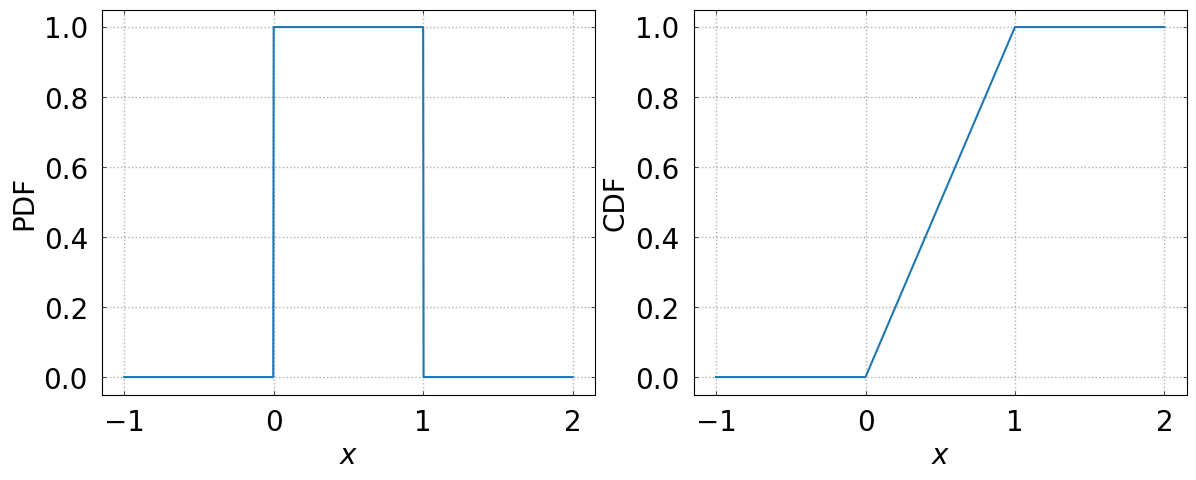

In [3]:
# example for the uniform distribution

def f(x):  # PDF uniform between 0 and 1 and vanishing otherwise
    
    # x is assumed to be a numpy array
    
    y = np.full(x.shape, 1., dtype=float)
    cond = np.logical_or(x<0, x>1)
    y[cond] = 0.
    return y

def F(x): # CDF for uniform PDF
    
    y = x.copy()
    y[x<0] = 0
    y[x>1] = 1
    
    cond = np.logical_and(x<0, x>1)
    y[cond] = x[cond]
    
    return y

x = np.linspace(-1,2,1000)
    

fig,axes = plt.subplots(ncols=2, nrows=1, figsize=(14,5))

for ax in axes:

    ax.grid(True,linestyle=':',linewidth='1.')
    ax.xaxis.set_ticks_position('both')
    ax.yaxis.set_ticks_position('both')
    ax.tick_params('both',length=3,width=0.5,which='both',direction = 'in',pad=10)
    ax.set_xlabel('$x$')
    
ax1,ax2 = axes

ax1.plot(x,f(x))
ax2.plot(x,F(x))
    
ax1.set_ylabel('PDF');
ax2.set_ylabel('CDF');

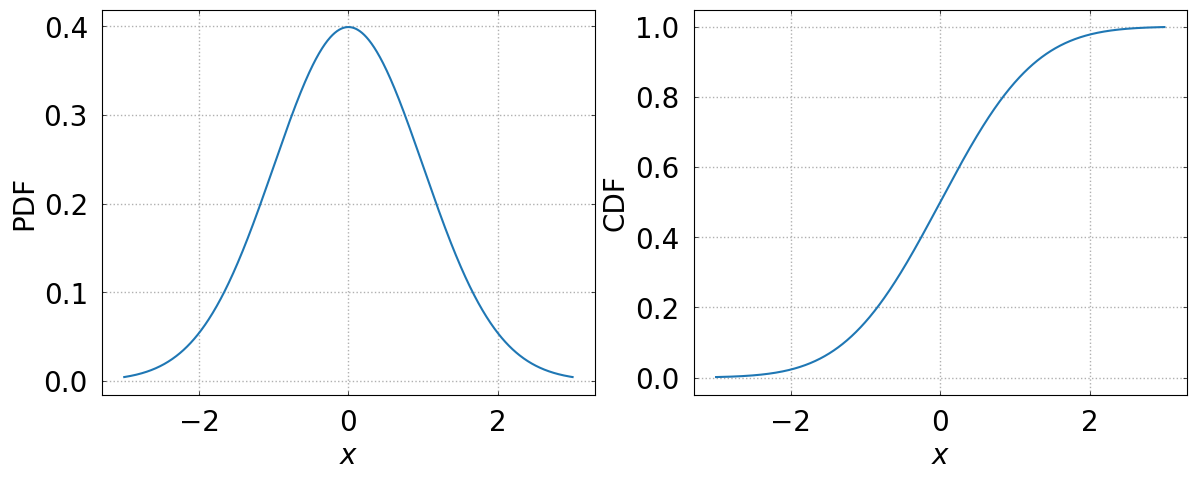

In [4]:
# example for the Gaussian distribution

from scipy.special import erf  # error function

def f(x):  # Gaussian PDF for mu=0 and sigma=1
    
    # x is assumed to be a numpy array
    
    return (1/np.sqrt(2*np.pi)) * np.exp(-x**2/2)

def F(x): # CDF for uniform PDF
    
    return 0.5 * (1 + erf(x/np.sqrt(2)))

x = np.linspace(-3,3,1000)
    
fig,axes = plt.subplots(ncols=2, nrows=1, figsize=(14,5))

for ax in axes:

    ax.grid(True,linestyle=':',linewidth='1.')
    ax.xaxis.set_ticks_position('both')
    ax.yaxis.set_ticks_position('both')
    ax.tick_params('both',length=3,width=0.5,which='both',direction = 'in',pad=10)
    ax.set_xlabel('$x$')
    
ax1,ax2 = axes

ax1.plot(x,f(x))
ax2.plot(x,F(x))
    
ax1.set_ylabel('PDF');
ax2.set_ylabel('CDF');

<u>EXERCISE</u>. 

Plot PDF and CDF for a sum of Gaussian distributions. For example, you can take one distribution to be the default (with zero mean and unit sigma) and the other one to be a shifted Gaussian (with some nonzero mean and, maybe, a sigma that is different from unity). 

### Sampling method 1 (inversion)

If we know the CDF of a distribution, we can sample from it! By its definition, $F$ viewed as a random variable is distributed uniformly between $0$ and $1$ *always*. Therefore, the algorithm:

- draw a sample $F_0$ uniformly in $[0,1]$ (this will be a random value of $F$);
- find such $x_0$ that $F(x_0)=F_0$, i.e. invert the function $F(x)$. The $x_0$ obtained will be a sample from our original distribution.

Caveats:

- $F(x)$ may be difficult to compute analytically (we need to integrate $f(x)$);
- It may be difficult to find the inverse of $F(x)$;

#### Example (a good function)

$$
f(x) = \frac{1}{2(\sqrt{2}-1)}\frac{1}{\sqrt{x}}\,, \qquad x\in[1,2] \quad \mbox{($f(x)=0$ otherwise)}
$$

$$
F(x<1)=0\,, \qquad F(x>2)=1
$$

$$
F(x) = \frac{\sqrt{x}-1}{\sqrt{2}-1}
$$

$$
x_{\rm samples} = \left[1 + F_{\rm samples}\left(\sqrt{2}-1\right)\right]^2
$$

Text(0, 0.5, 'PDF')

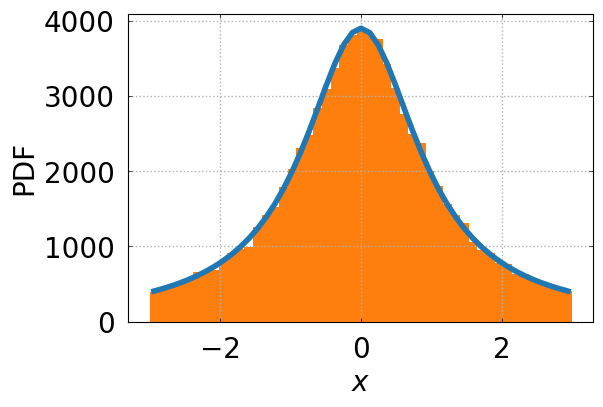

In [14]:
sample_size = 100000

F_samples = np.random.random(sample_size)
#x_samples = (1 + F_samples*(np.sqrt(2)-1))**2

x_samples = np.tan(np.pi*(F_samples-1./2))

x = np.linspace(-3,3, 100)

fig,ax = plt.subplots(ncols=1, nrows=1, figsize=(6,4))


# ax.set_xscale('log')
# ax.set_yscale('log')

# ax.plot(x, 1/2/np.sqrt(x)/(np.sqrt(2)-1), lw=4)
# ax.hist(x_samples, bins=50, density=True)

bins = np.linspace(-3,3,50)

xm = (bins[1:]+bins[:-1])/2
dx = bins[1:] - bins[:-1]

ax.plot(xm, dx*sample_size/np.pi/(1+xm**2), lw=4)
ax.hist(x_samples, bins=bins, density=False)





ax.grid(True,linestyle=':',linewidth='1.')
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params('both',length=3,width=0.5,which='both',direction = 'in',pad=10)

ax.set_xlabel('$x$')
ax.set_ylabel('PDF')

#### Example (a not so good function)

$$
f(x) = \frac{1}{\sqrt{2\pi}}\exp{\left\{-\frac{x^2}{2}\right\}}
$$

$$
F(x) = \frac 12 + \frac 12{\rm erf}\left(\frac{x}{\sqrt{2}}\right)
$$

$$
x_{\rm samples} = \sqrt{2}\,{\rm erf}^{-1}\left(2F_{\rm samples}-1\right)
$$

Text(0, 0.5, 'PDF')

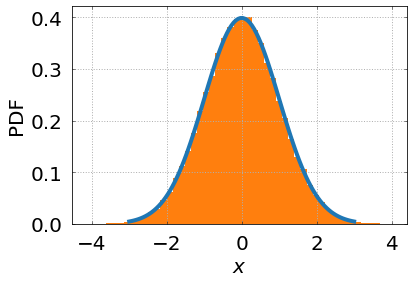

In [5]:
from scipy.special import erfinv

sample_size = 100000

F_samples = np.random.random(sample_size)
x_samples = np.sqrt(2) * erfinv(2*F_samples - 1)

x = np.linspace(-3,3, 100)

fig,ax = plt.subplots(ncols=1, nrows=1, figsize=(6,4))


# ax.set_xscale('log')
# ax.set_yscale('log')

ax.plot(x, (1/np.sqrt(2*np.pi)) * np.exp(-x**2/2), lw=4)
ax.hist(x_samples, bins=50, density=True)





ax.grid(True,linestyle=':',linewidth='1.')
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params('both',length=3,width=0.5,which='both',direction = 'in',pad=10)

ax.set_xlabel('$x$')
ax.set_ylabel('PDF')

<u>EXERCISE</u>. 

The chi-squared distribution ($\chi^2$-distribution) with $k$ degrees of freedom (notation: $\chi^2_k$) is the distribution of the sum of $k$ squared Gaussian variables (with zero mean and unit sigma). For $k=2$, its PDF

$$
f(x) = \frac 12 e^{-\frac x2}\,, \qquad x\geq 0\,.
$$

Note that $x$ is non-negative, because the variable $x$ is the sum of the squares of Gaussian variables.

1. What is the respective CDF?
2. Double check that $f(x)$ makes sense starting from Gaussian samples:
   - generate two Gaussian samples with `np.random.randn(...)`, 
   - square them and sum up the squares, 
   - plot a histogram (with `density=True`).
3. Sample from the $\chi^2_2$ distribution using the inversion sampling method.

### Sampling method 2 (rejection, v1.0)

It is a geometric technique. We throw points in the plane PDF vs. $x$. Points above the graph are rejected and below the graph, accepted as samples.

The algorithm:

- choose a rectangular region (a box) of the plane that contains the PDF's plot;
- generate a uniformly distributed sample along the vertical span of the region (that would the $y$'s of the points);
- generate a uniformly distributed sample along the horizontal span of the region (that would the $x$'s of the points);
- for each point, if it happens to be above the plot (that is, $y>f(x)$), reject it; if it is below the plot (that is, $y<f(x)$), accept it.

Caveats:

- the vertical span must be higher than the PDF's maximum, but should not be too high (otherwise, it will take long to get a sufficient number of samples);
- for PDFs that span the entire real axis, one should come up with a transformation to "compactify" the real axis to a finite interval (for example, $x'=\tan^{-1}{x}$ transform $\mathbb{R}$ to $(-\frac{\pi}{2},\frac{\pi}{2})$)

#### Example (the good function above)

$$
f(x) = \frac{1}{2(\sqrt{2}-1)}\frac{1}{\sqrt{x}}\,, \qquad x\in[1,2] \quad \mbox{($f(x)=0$ otherwise)}
$$

In [6]:
def f(x):
    
    y = np.full_like(x, 0., dtype=float)
    cond = np.logical_and(x>1,x<2)
    y[cond] = 1/2/np.sqrt(x[cond])/(np.sqrt(2)-1)
    return y

x = np.linspace(0,3, 500)

print('The maximum value: ', f(x).max())

The maximum value:  1.2046949770165376


Sample size: 76661
Fraction of the initial size: 76.66%


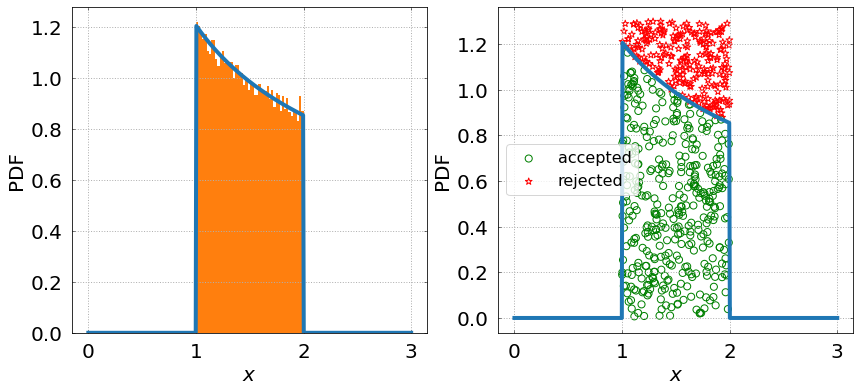

In [7]:
init_size = 100000

y_max = 1.3

x_pts = 1 + np.random.random(init_size)  # [1,2]
y_pts = y_max*np.random.random(init_size) # [0, y_max]

accept_cond = f(x_pts) > y_pts
x_samples = x_pts[accept_cond]

sample_size = len(x_samples)
print('Sample size:', sample_size)
print('Fraction of the initial size: {:.2f}%'.format(100*sample_size/init_size))

fig,axes = plt.subplots(ncols=2, nrows=1, figsize=(14,6))

for ax in axes:

    ax.grid(True,linestyle=':',linewidth='1.')
    ax.xaxis.set_ticks_position('both')
    ax.yaxis.set_ticks_position('both')
    ax.tick_params('both',length=3,width=0.5,which='both',direction = 'in',pad=10)
    ax.set_xlabel('$x$')
    ax.set_ylabel('PDF')
    
ax1,ax2 = axes


ax1.plot(x, f(x), lw=4)
ax1.hist(x_samples, bins=50, density=True);

ax2.plot(x, f(x), lw=4)
ax2.scatter(x_pts[accept_cond][::200], y_pts[accept_cond][::200],\
            s=50, marker='o', fc='none', ec='green', label='accepted')
ax2.scatter(x_pts[~accept_cond][::100], y_pts[~accept_cond][::100],\
            s=50, marker='*', fc='none', ec='red', label='rejected')

ax2.legend()




<u>EXERCISE</u>. 

The rejection method does not require a normalized PDF as long as we choose the vertical size of the box bigger than the maximum value of the distribution. Sample from a distribution that is proportional to $x^2$ on $[-2,2]$ and vanishes otherwise.

<u>EXERCISE</u>. 

Sample from the Gaussian distribution with zero mean and unit sigma.

- although its PDF goes from $-\infty$ to $+\infty$, choose a finite horizontal span for the box and sample using the rejection method;
- compare the result with the exact PDF;
- experiment with increasing the horizontal span and see how it affects the deviation from the exact PDF;
- (if there is time) if we introduce a new variable $x'=\tan^{-1}{x}$, the span becomes finite, $x'\in(-\frac{\pi}{2},\frac{\pi}{2})$, and we can sample in a finite box. However, the PDF gets modified:

$$
\tilde{f}(x') = \frac{1}{\sqrt{2\pi}}\frac{\exp{\left\{-\frac{(\tan{x'})^2}{2}\right\}}}{\cos^2{x'}}
$$

Sample from it and convert the samples $x'$ to the "old" variable $x=\tan{x'}$. Note that the end points $x'=\pm\frac{\pi}{2}$ are singular points for $f(x')$ (it is undefined there). So, you need to generate the samples in a smaller interval, e.g. $(-\frac{\pi}{2}+10^{-5},\frac{\pi}{2}-10^{-5})$.

### Sampling method from 2D distributions

Sometimes we need to sample in more than one dimension. For example, we want to model a specific mass density of a body and sample points according to that density.
 

<u>EXAMPLE</u>

Uniform distribution in a circle

One way is to sample points uniformly in a square that contains the circle and then pick only those points that are inside the circle.

Text(0, 0.5, '$x_2$')

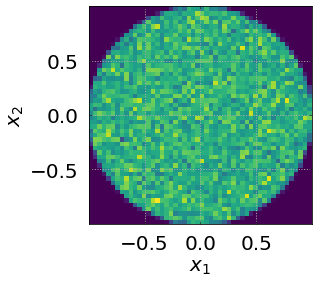

In [9]:
# unit circle R=1

init_size = 100000

x1 = 2*np.random.random(init_size) - 1  # [-1,1]
x2 = 2*np.random.random(init_size) - 1  # [-1,1]

R = np.sqrt(x1**2 + x2**2)

cond = R<1
x1_sample = x1[cond]
x2_sample = x2[cond]

fig,ax = plt.subplots(ncols=1, nrows=1, figsize=(4,4))

#ax.scatter(x1_sample, x2_sample, s=10)
ax.hist2d(x1_sample, x2_sample, bins=50)



ax.grid(True,linestyle=':',linewidth='1.')
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params('both',length=3,width=0.5,which='both',direction = 'in',pad=10)

ax.set_xlabel('$x_1$')
ax.set_ylabel('$x_2$')

Another way involves some calculus. Instead of sampling in the Cartesian coordinates $(x_1,x_2)$, we can sample in polar coordinates $(r,\phi)$. One related to the other by
$$
x_1 = r\cos\phi\,, \qquad x_2 = r\sin\phi
$$


The probability for a point to end up in an area ${\rm d}A$ is proportional to that area:

$$
\frac{{\rm d}A}{\pi} = \frac{{\rm d}x_1\,{\rm d}x_2}{\pi} = \frac{r\,{\rm d}r\,{\rm d}\phi}{\pi} = \frac{{\rm d}\phi}{2\pi}\frac{{\rm d}(r^2)}{1}.
$$

That is, $\phi$ is uniform in $[0,2\pi]$, and $r^2$ is uniform in $[0,1]$ ($[0,R^2]$ if the radius of the circle is different from one).

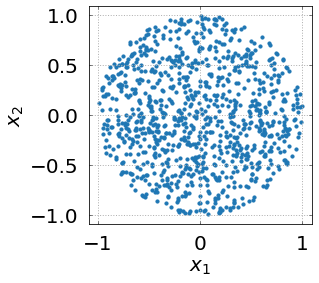

In [20]:
init_size = 1000

phi = 2*np.pi*np.random.random(init_size)  # [0,2*np.pi]
r_squared = np.random.random(init_size)  # [0,1]

r = np.sqrt(r_squared)

x1_sample = r*np.cos(phi)
x2_sample = r*np.sin(phi)

fig,ax = plt.subplots(ncols=1, nrows=1, figsize=(4,4))

ax.scatter(x1_sample, x2_sample, s=10)



ax.grid(True,linestyle=':',linewidth='1.')
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params('both',length=3,width=0.5,which='both',direction = 'in',pad=10)

ax.set_xlabel('$x_1$')
ax.set_ylabel('$x_2$');

<u>EXAMPLE</u>

The "calculus method" also works when we want to sample points that follow a specific density distribution. Let's say we have a massive unit disk with a sheet density $\Sigma\propto r$. (Sheet density means that the mass of a small area ${\rm d}A$ is $\Sigma\,{\rm d}A$). That is, the disk gets heavier closer to its edge. 

If we want to distribute points proportional to the density, the probability to find a point in an area ${\rm d}A$ is

$$
\propto \Sigma\,{\rm d}A = \Sigma\,{\rm d}\phi\,r\,{\rm d}r \propto {\rm d}\phi\,r^2{\rm d}r \propto {\rm d}\phi\,{\rm d}(r^3) 
$$

Note that we have omitted the prefactors. And we do not need them to see that $\phi$ is uniform (still in $[0,2\pi]$, because that is the range for $\phi$), and $r^3$ is uniform (in its own range; $[0,1]$ for the unit disk).

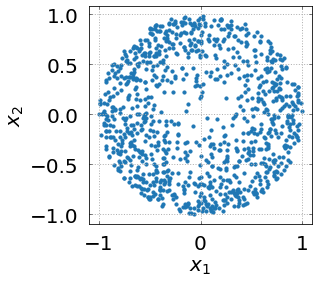

In [21]:
init_size = 1000

phi = 2*np.pi*np.random.random(init_size)  # [0,2*np.pi]
r_cubed = np.random.random(init_size)  # [0,1]

r = r_cubed**(1./3)

x1_sample = r*np.cos(phi)
x2_sample = r*np.sin(phi)

fig,ax = plt.subplots(ncols=1, nrows=1, figsize=(4,4))

ax.scatter(x1_sample, x2_sample, s=10)



ax.grid(True,linestyle=':',linewidth='1.')
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params('both',length=3,width=0.5,which='both',direction = 'in',pad=10)

ax.set_xlabel('$x_1$')
ax.set_ylabel('$x_2$');

<u>EXERCISE</u>

Think of a sheet density for the disk, so that it is heavier in the center and lighter by its edge. Find the distributions for $\phi$ and $r$ and sample from them. Plot the sample.

#### Using the "calculus method" to sample from a 1D Gaussian PDF

What if we sample both $x_1$ and $x_2$ from the Gaussian PDF? How will $\phi$ and $r$ be distributed?

Text(0, 0.5, '$x_2$')

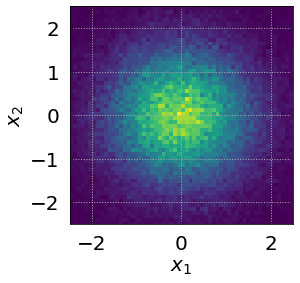

In [31]:
init_size = 100000

x1 = np.random.randn(init_size) # Gaussian
x2 = np.random.randn(init_size) # Gaussian

fig,ax = plt.subplots(ncols=1, nrows=1, figsize=(4,4))

ax.hist2d(x1, x2, bins=100, density=True)



ax.grid(True,linestyle=':',linewidth='1.')
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params('both',length=3,width=0.5,which='both',direction = 'in',pad=10)

ax.set_xlim(-2.5,2.5)
ax.set_ylim(-2.5,2.5)

ax.set_xlabel('$x_1$')
ax.set_ylabel('$x_2$')

Hm, that looks radially symmetric, so in the polar coordinates, $\phi$ is uniform. What about $r$?

$$
\frac{{\rm d}x_1}{\sqrt{2\pi}}\exp{\left\{-\frac{x_1^2}{2}\right\}}\times\frac{{\rm d}x_2}{\sqrt{2\pi}}\exp{\left\{-\frac{x_2^2}{2}\right\}} = \frac{{\rm d}\phi}{2\pi}\,\exp{\left\{-\frac{r^2}{2}\right\}}\,r\,{\rm d}r
$$

$$
e^{-\frac{r^2}{2}}\,r\,{\rm d}r = e^{-\frac{r^2}{2}}\,{\rm d}\left(\frac{r^2}{2}\right)
$$

Thus, if we denote $x\equiv r^2/2$, this new variable has PDF $f(x)=e^{-x}$, $x\geq 0$ (very similar to the $\chi_2^2$ distribution from an exercise above!). The inversion sampling is well suited to sample from this PDF.

<u>EXERCISE</u>

Reverse engineer the described process to get a 1D Gaussian sample:

- sample from the PDF just obtained using the inversion sampling;
- convert the sample in $x$ to a sample in $r$;
- sample $\phi$ uniformly;
- convert the samples in the polar coordinates to samples in the Cartesian coordinates $x_1$ and $x_2$;
- check that both $x_1$ and $x_2$ follow the 1D Gaussian distribution;

### Monte Carlo

Loosely, Monte Carlo methods are methods that involve generating samples and drawing conclusions based on those samples.

#### Integration

Sample size: 76995
Fraction of the initial size: 77.00%
The box's area: 1.3
The area under the curve: 1.000935


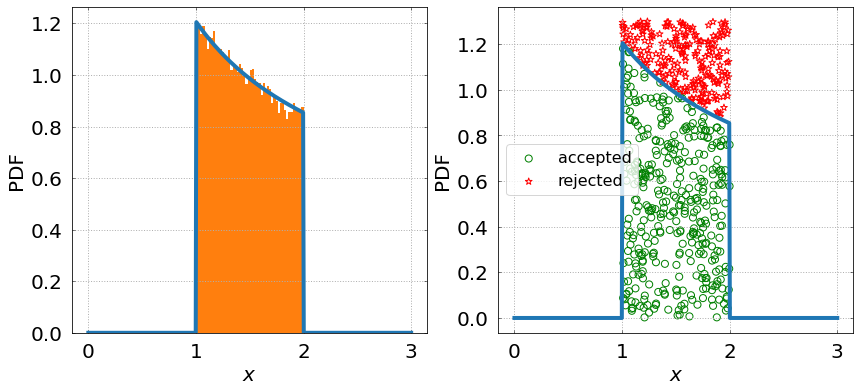

In [33]:
init_size = 100000

y_max = 1.3

x_pts = 1 + np.random.random(init_size)  # [1,2]
y_pts = y_max*np.random.random(init_size) # [0, y_max]

accept_cond = f(x_pts) > y_pts
x_samples = x_pts[accept_cond]

sample_size = len(x_samples)
print('Sample size:', sample_size)
print('Fraction of the initial size: {:.2f}%'.format(100*sample_size/init_size))

box_area = y_max*1
print("The box's area:", box_area)
print("The area under the curve:", box_area * sample_size/init_size)

fig,axes = plt.subplots(ncols=2, nrows=1, figsize=(14,6))

for ax in axes:

    ax.grid(True,linestyle=':',linewidth='1.')
    ax.xaxis.set_ticks_position('both')
    ax.yaxis.set_ticks_position('both')
    ax.tick_params('both',length=3,width=0.5,which='both',direction = 'in',pad=10)
    ax.set_xlabel('$x$')
    ax.set_ylabel('PDF')
    
ax1,ax2 = axes


ax1.plot(x, f(x), lw=4)
ax1.hist(x_samples, bins=50, density=True);

ax2.plot(x, f(x), lw=4)
ax2.scatter(x_pts[accept_cond][::200], y_pts[accept_cond][::200],\
            s=50, marker='o', fc='none', ec='green', label='accepted')
ax2.scatter(x_pts[~accept_cond][::100], y_pts[~accept_cond][::100],\
            s=50, marker='*', fc='none', ec='red', label='rejected')

ax2.legend()


#### An example: Center of mass

$$
x^{\rm CoM}_1 = \frac{x^{(1)}_1{\rm d}m^{(1)}+x^{(2)}_1{\rm d}m^{(2)}+\ldots}{m_{\rm tot}}
$$

$$
x^{\rm CoM}_2 = \frac{x^{(1)}_2{\rm d}m^{(1)}+x^{(2)}_2{\rm d}m^{(2)}+\ldots}{m_{\rm tot}}
$$

(-0.1618597480672893, -0.0005575095451365024)

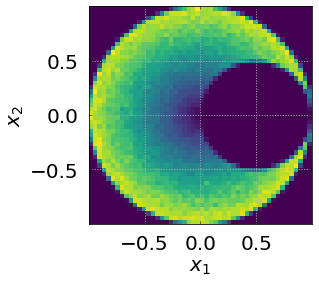

In [22]:
init_size = 1000000

phi = 2*np.pi*np.random.random(init_size)  # [0,2*np.pi]
r_cubed = np.random.random(init_size)  # [0,1]

r = r_cubed**(1./3)

x1_sample = r*np.cos(phi)
x2_sample = r*np.sin(phi)

r0 = 1/2
cond = (x1_sample - 0.5)**2 + x2_sample**2 > r0**2

fig,ax = plt.subplots(ncols=1, nrows=1, figsize=(4,4))

#ax.scatter(x1_sample[cond], x2_sample[cond], s=10)
ax.hist2d(x1_sample[cond], x2_sample[cond], bins=50)



ax.grid(True,linestyle=':',linewidth='1.')
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params('both',length=3,width=0.5,which='both',direction = 'in',pad=10)

ax.set_xlabel('$x_1$')
ax.set_ylabel('$x_2$');

np.mean(x1_sample[cond]), np.mean(x2_sample[cond])

## Home exercises

<font size="3">(completing one is required; completing more is recommended)</font>

#### 1. An example of inversion sampling

- using the inversion method, sample from PDF

$$
f(x)= \frac{1}{\pi}\frac{1}{1+x^2}\,, \qquad x\in(-\infty,+\infty)
$$

- plot both the histogram of the sample and the PDF; do they agree?

*Hint*. To calculate a simple integral, one can use, for example, https://www.wolframalpha.com/, where you type in something like "integrate 1/x^2 from 1 to +inf". For more complicated integrals, that webpage may refuse to calculate, but that should not be the case.

#### 2. An example of rejection sampling + Monte Carlo modeling

The masses of stars in a galaxy approximately follow a power-law distribution. More precisely, stars with masses between 1 and 100 solar masses are distributed as follows:

$$
\mbox{PDF}\propto\frac{1}{m^{2.3}}\,, \qquad 1<m<100
$$

where $m$ is the mass of a star in solar masses. For this problem, we also assume that there are no stars lighter than the Sun (one solar mass) and heavier than 100 solar masses. (In astronomy, a distribution in mass is referred to as *mass function*).

Now, consider a star cluster with a total mass of $\approx 10^6$ solar masses. Using rejection sampling, generate a sample of stars, so that their total mass is approximately $10^6$ solar masses:

- choose an initial sample size;
- generate a sample with that size from the PDF (mass function) given above;
- calculate the sum of the masses in that sample (you can use `np.sum(...)`);
- if the sum is smaller than $10^6$, double the sample size and repeat the steps above until the total mass exceeds $10^6$ (we do *not* need exactly a million, something between $10^6$ and $10^7$ will do);
- if the sum is bigger than $10^7$, cut the sample size in half and repeat the steps for sample generation;
- if the sum is between $10^6$ and $10^7$, this is our final sample (the mass is *on the order of* a million);

Having generated the sample, answer some questions about the star cluster:

- approximately, how many stars are there in the cluster?
- what is the mean mass of a star?
- stars heavier than 20 solar masses are known to turn into black holes when they run out of "fuel" (mainly, hydrogen). How many black holes can we expect in that cluster after some time? 

(FYI: the heavier-than-20 stars run out of "fuel" quickly, astrophysically speaking - in a few million years; for comparison, the age of our Sun is about 5 billion years.)

#### 3. The PDF of the maximum of two values sampled from a PDF $f(x)$

Let us consider the maximum of two random values drawn from a PDF $f(x)$ one after the other. We can continue this process and generate a sample of the maxima. It turns out that the CDF for that sample is $F^2(x)$, and therefore, the PDF is $(F^2)' = 2FF' = 2fF$ (because $f(x)$ is a derivative of $F(x)$).

Generate a sample of the maxima for one of the functions used in the tutorial:

$$
f(x) = \frac{1}{2(\sqrt{2}-1)}\frac{1}{\sqrt{x}}\,, \qquad x\in[1,2] \quad \mbox{($f(x)=0$ otherwise)}
$$

To that end:

- choose a sample size;
- generate *two* samples of that size (with a method you like);
- generate a sample of the maxima from the previous two samples. That is, we take the 1st elements from each sample and choose a bigger one, then we take the 2nd elements from each sample and choose a bigger one, etc. You can use function `np.maximum(sample1, sample2)`.
- plot a histogram of the new sampled obtained (with `density=True`) and compare to the expected PDF $2fF$ (we have computed $F$ in the tutorial);

